<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_ch06_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_ch06_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory Ch 6 — Figure Notebook
**String Interactions**

In [1]:
FIG_DIR = 'figures/ch06'

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
SKYB='#89c4f4';YELL='#f9c74f';GREEN='#90ee90'
RED='#e07070';PURP='#c792ea';ORAN='#e8a838';TEAL='#2ec4b6'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,
    'text.color':FG,'axes.labelcolor':FG,
    'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.25,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':SKYB,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})
os.makedirs(FIG_DIR, exist_ok=True)

def save(name, fig):
    fig.savefig(f'{FIG_DIR}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show(); print(f'Saved: {FIG_DIR}/{name}')

print('Setup complete.')


Setup complete.


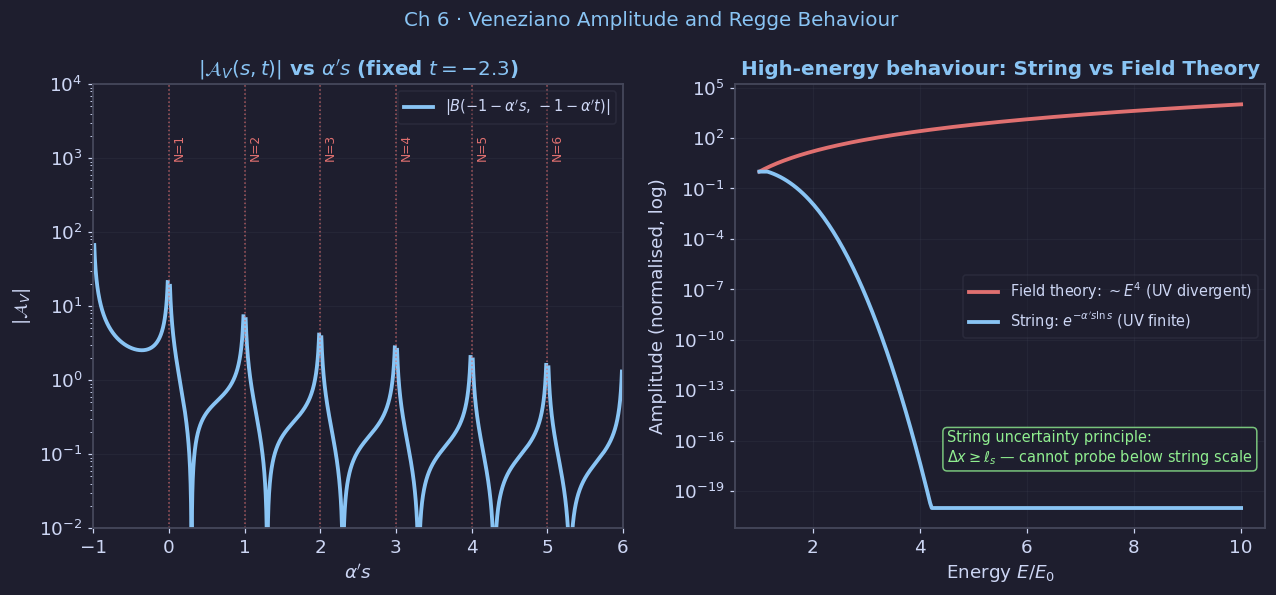

Saved: figures/ch06/fig01_veneziano.png


In [2]:
# ── fig01: Veneziano amplitude ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 6 · Veneziano Amplitude and Regge Behaviour', color=SKYB, fontsize=13)

from scipy.special import gamma as Gamma

# ── Left: Veneziano amplitude ─────────────────────────────────────────────
from scipy.special import beta as Beta

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'$|\mathcal{A}_V(s,t)|$ vs $\alpha^{\prime}s$ (fixed $t=-2.3$)',
             color=SKYB)

alpha_prime = 1.0
t_fixed = -2.3
b = -1 - alpha_prime * t_fixed   # = 1.3, 상수

pole_positions = np.arange(-1, 7, 1)   # s = -1, 0, 1, 2, 3, 4, 5, 6

for i in range(len(pole_positions) - 1):
    s_lo = pole_positions[i] + 0.015
    s_hi = pole_positions[i+1] - 0.015
    s_seg = np.linspace(s_lo, s_hi, 500)
    A_seg = np.zeros_like(s_seg)
    for j, s in enumerate(s_seg):
        a = -1 - alpha_prime * s
        try:
            val = abs(Beta(a, b))
            A_seg[j] = val if np.isfinite(val) else np.nan
        except Exception:
            A_seg[j] = np.nan
    # pole 근처 발산 부분은 nan으로 처리 (clip 대신)
    A_display = np.where(A_seg < 1e4, A_seg, np.nan)
    ax.semilogy(s_seg, A_display, color=SKYB, lw=2.5)

# legend용 dummy line
ax.semilogy([], [], color=SKYB, lw=2.5,
            label=r'$|B(-1-\alpha^{\prime}s,\,-1-\alpha^{\prime}t)|$')

# resonance pole 위치 표시
for n, s_pole in enumerate(pole_positions[1:-1]):   # s = 0, 1, 2, 3, 4, 5
    ax.axvline(s_pole, color=RED, lw=1, ls=':', alpha=0.7)
    ax.text(s_pole + 0.05, 1e3, f'N={n+1}', fontsize=8,
            color=RED, rotation=90)

ax.set_xlabel(r'$\alpha^{\prime}s$')
ax.set_ylabel(r'$|\mathcal{A}_V|$')
ax.legend(fontsize=9.5)
ax.grid(True, alpha=0.2)
ax.set_xlim(-1, 6)
ax.set_ylim(1e-2, 1e4)



# ── Right: high-energy behaviour ──────────────────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title('High-energy behaviour: String vs Field Theory', color=SKYB)
E = np.linspace(1, 10, 300)

# Field theory: power-law growth
A_FT = E**4

# String: Virasoro-Shapiro fixed-angle behaviour
# |A| ~ exp(-alpha'/2 * (s*ln s + t*ln|t| + u*ln|u|))
# Fixed angle: s large, t = -s*sin^2(theta/2), u = -s*cos^2(theta/2)
theta = np.pi / 3
s_str = E**2
t_str = s_str * np.sin(theta/2)**2   # |t|, positive
u_str = s_str * np.cos(theta/2)**2   # |u|, positive

# Exponent (all arguments positive now)
exponent = (alpha_prime / 2) * (
    s_str * np.log(s_str) +
    t_str * np.log(t_str) +
    u_str * np.log(u_str)
)
A_string = np.exp(-np.clip(exponent, 0, 200))

ax2.semilogy(E, A_FT / A_FT[0], color=RED, lw=2.5,
             label=r'Field theory: $\sim E^4$ (UV divergent)')
ax2.semilogy(E, np.clip(A_string / A_string[0], 1e-20, None),
             color=SKYB, lw=2.5,
             label=r'String: $e^{-\alpha^{\prime}s\ln s}$ (UV finite)')

ax2.set_xlabel(r'Energy $E/E_0$')
ax2.set_ylabel('Amplitude (normalised, log)')
ax2.legend(fontsize=9.5); ax2.grid(True, alpha=0.2)
ax2.text(0.40, 0.15,
         'String uncertainty principle:\n'
         r'$\Delta x \geq \ell_s$ — cannot probe below string scale',
         transform=ax2.transAxes, fontsize=9.5, color=GREEN,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

plt.tight_layout()
save('fig01_veneziano.png', fig)

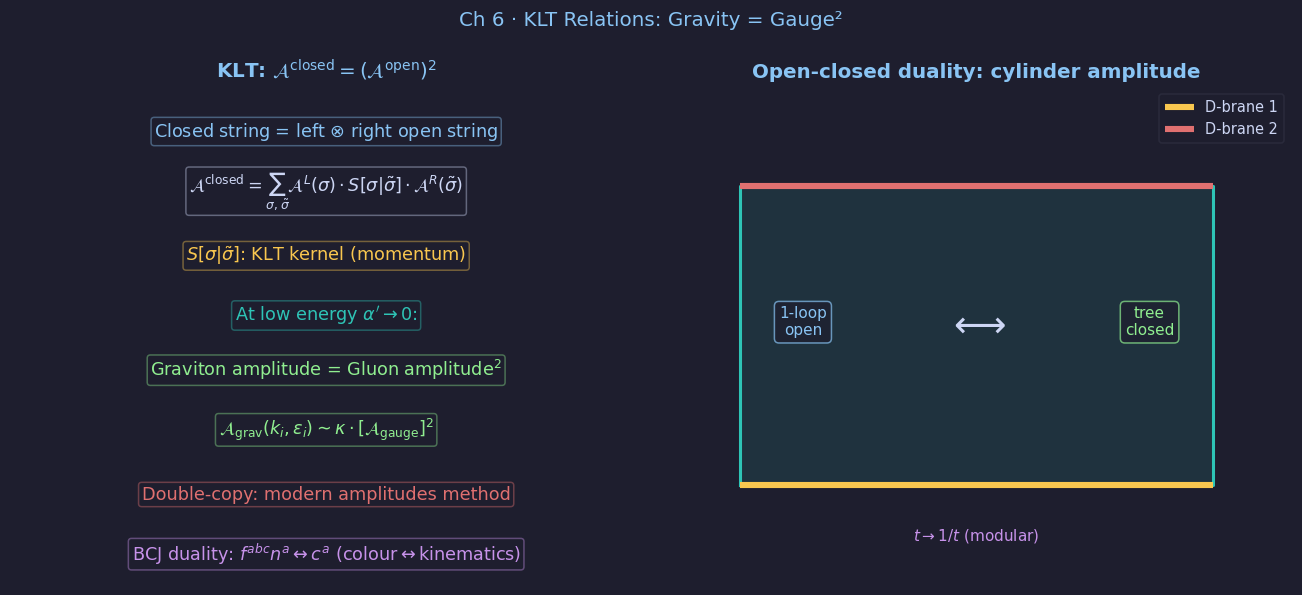

Saved: figures/ch06/fig02_klt_open_closed.png


In [3]:

# ── fig02: KLT relations and open-closed duality ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 6 · KLT Relations: Gravity = Gauge²', color=SKYB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'KLT: $\mathcal{A}^{\rm closed}=(\mathcal{A}^{\rm open})^2$',
             color=SKYB)
items = [
    (0.5, 0.91, r'Closed string = left $\otimes$ right open string', SKYB),
    (0.5, 0.79, r'$\mathcal{A}^{\rm closed}=\sum_{\sigma,\tilde\sigma}\mathcal{A}^L(\sigma)\cdot S[\sigma|\tilde\sigma]\cdot\mathcal{A}^R(\tilde\sigma)$', FG),
    (0.5, 0.66, r'$S[\sigma|\tilde\sigma]$: KLT kernel (momentum)', YELL),
    (0.5, 0.54, r'At low energy $\alpha^{\prime}\to 0$:', TEAL),
    (0.5, 0.43, r'Graviton amplitude = Gluon amplitude$^2$', GREEN),
    (0.5, 0.31, r'$\mathcal{A}_{\rm grav}(k_i,\epsilon_i)\sim\kappa\cdot[\mathcal{A}_{\rm gauge}]^2$', GREEN),
    (0.5, 0.18, r'Double-copy: modern amplitudes method', RED),
    (0.5, 0.06, r'BCJ duality: $f^{abc}n^a \leftrightarrow c^a$ (colour$\leftrightarrow$kinematics)', PURP),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=11.5,color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

# Right: open-closed duality diagram
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title('Open-closed duality: cylinder amplitude', color=SKYB)
ax2.set_xlim(0, 4); ax2.set_ylim(0, 4); ax2.axis('off')

# Draw cylinder schematic as rectangle
ax2.fill_between([0.5,3.5], [0.8,0.8], [3.2,3.2],
                 color=TEAL, alpha=0.12)
ax2.plot([0.5,3.5,3.5,0.5,0.5], [0.8,0.8,3.2,3.2,0.8],
         color=TEAL, lw=2)

# D-brane lines at top and bottom
ax2.hlines(0.8, 0.5, 3.5, colors=YELL, lw=4, label='D-brane 1')
ax2.hlines(3.2, 0.5, 3.5, colors=RED,  lw=4, label='D-brane 2')

# Open string loop (horizontal)
ax2.text(2, 2.0, r'$\longleftrightarrow$', ha='center', fontsize=24, color=FG)
ax2.text(0.9, 2.0, '1-loop\nopen', ha='center', fontsize=10, color=SKYB,
         bbox=dict(boxstyle='round', fc=BG, ec=SKYB, alpha=0.7))
ax2.text(3.1, 2.0, 'tree\nclosed', ha='center', fontsize=10, color=GREEN,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))
ax2.text(2, 0.35, r'$t\to 1/t$ (modular)', ha='center', fontsize=10, color=PURP)
ax2.legend(fontsize=9.5, loc='upper right')

plt.tight_layout()
save('fig02_klt_open_closed.png', fig)


In [4]:
# ── Download all figures as a zip ────────────────────────────────────────
import shutil

shutil.make_archive('ch06_figures', 'zip', 'figures/ch06')

try:
    from google.colab import files
    files.download('ch06_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch06/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
